# Public Transport Delay Risk Prediction System
## Data cleaning, exploratory data analysis, model training, and model export

This notebook trains a **bus delay-risk classifier**. The target is defined as:
- `1` = predicted delay is **30 minutes or more**
- `0` = predicted delay is **less than 30 minutes**

Important correction: `How_Long_Delayed` is kept unchanged until the target is created. Missing or unreadable delay values are not filled with the most common delay, because that would create made-up target labels.

## 1. Import libraries

In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import re
from pathlib import Path

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report
)
import joblib

## 2. Load the dataset

The notebook checks the project path first, then the current folder. If neither file exists, place the CSV beside this notebook or update `DATA_PATHS`.

In [7]:
df = pd.read_csv(r"C:\Users\Deepak\OneDrive\Documents\DESKTOP\FP\Bus_Breakdown_and_Delays_20260822.csv")

C:\Users\Deepak\AppData\Local\Temp\ipykernel_2000\3979777745.py:1: DtypeWarning: Columns (0: Reason, 1: Incident_Number) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(r"C:\Users\Deepak\OneDrive\Documents\DESKTOP\FP\Bus_Breakdown_and_Delays_20260822.csv")


## 3. Initial inspection

In [8]:
print("Shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())
print("\nData types:")
display(df.dtypes)
print("\nMissing values:")
display(df.isnull().sum().sort_values(ascending=False).head(20))
print("\nDuplicate rows:", df.duplicated().sum())

Shape: (1294129, 21)

Column names:
['School_Year', 'Busbreakdown_ID', 'Run_Type', 'Bus_No', 'Route_Number', 'Reason', 'Schools_Serviced', 'Occurred_On', 'Created_On', 'Boro', 'Bus_Company_Name', 'How_Long_Delayed', 'Number_Of_Students_On_The_Bus', 'Has_Contractor_Notified_Schools', 'Has_Contractor_Notified_Parents', 'Have_You_Alerted_OPT', 'Informed_On', 'Incident_Number', 'Last_Updated_On', 'Breakdown_or_Running_Late', 'School_Age_or_PreK']

Data types:


School_Year                           str
Busbreakdown_ID                     int64
Run_Type                              str
Bus_No                                str
Route_Number                          str
Reason                                str
Schools_Serviced                      str
Occurred_On                           str
Created_On                            str
Boro                                  str
Bus_Company_Name                      str
How_Long_Delayed                      str
Number_Of_Students_On_The_Bus         str
Has_Contractor_Notified_Schools       str
Has_Contractor_Notified_Parents       str
Have_You_Alerted_OPT                  str
Informed_On                           str
Incident_Number                    object
Last_Updated_On                       str
Breakdown_or_Running_Late             str
School_Age_or_PreK                    str
dtype: object


Missing values:


Incident_Number                    1281634
How_Long_Delayed                    179895
Reason                              144304
Boro                                 24079
Schools_Serviced                      3629
Bus_Company_Name                      3492
Route_Number                           135
Number_Of_Students_On_The_Bus           71
Bus_No                                  60
Run_Type                                30
School_Year                              1
Occurred_On                              1
Created_On                               1
Last_Updated_On                          1
Informed_On                              1
Busbreakdown_ID                          0
Has_Contractor_Notified_Schools          0
Have_You_Alerted_OPT                     0
Has_Contractor_Notified_Parents          0
Breakdown_or_Running_Late                0
dtype: int64


Duplicate rows: 0


In [9]:
display(df.describe(include="all").T.head(30))

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
School_Year,1294128,32,2018-2019,112881,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Busbreakdown_ID,1294129.0,NaN,NaN,NaN,1437259.642224,379599.004096,780851.0,1108414.0,1436932.0,1762273.0,2096647.0
Run_Type,1294099,10,Special Ed AM Run,786633,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Bus_No,1294069,31450,0000,1963,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Route_Number,1293994,23166,1,7653,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Reason,1149825,10,Heavy Traffic,680510,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Schools_Serviced,1290500,62867,12084,6170,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Occurred_On,1294128,577347,05/03/2010 07:30:00 AM,350,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Created_On,1294128,703959,09/15/2010 06:00:00 AM,99,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Boro,1270050,12,Brooklyn,315554,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 4. Remove duplicate records

In [10]:
df = df.drop_duplicates().copy()
print("Shape after removing duplicates:", df.shape)
print("Remaining duplicate rows:", df.duplicated().sum())

Shape after removing duplicates: (1294129, 21)
Remaining duplicate rows: 0


## 5. Convert delay text into numeric minutes

The original delay column contains text such as `16-30 Min`, `30min`, and `20 MINS`. The parser:
- uses the midpoint for a range such as `16-30 Min`;
- handles hour-based text when present;
- returns a missing value when no number can be read.

In [11]:
def parse_delay_minutes(value):
    if pd.isna(value):
        return np.nan

    text = str(value).strip().lower().replace(",", "")
    if not text or text in {"nan", "none", "n/a", "na", "unknown"}:
        return np.nan

    # Handle formats such as "1 hour 30 min"
    hour_match = re.search(r"(\d+(?:\.\d+)?)\s*(?:hour|hours|hr|hrs)\b", text)
    minute_match = re.search(r"(\d+(?:\.\d+)?)\s*(?:minute|minutes|min|mins)\b", text)
    if hour_match:
        hours = float(hour_match.group(1))
        minutes = float(minute_match.group(1)) if minute_match else 0.0
        return hours * 60 + minutes

    # Handle ranges such as "16-30 Min" or "30–60 minutes"
    range_match = re.search(r"(\d+(?:\.\d+)?)\s*[-–]\s*(\d+(?:\.\d+)?)", text)
    if range_match:
        low = float(range_match.group(1))
        high = float(range_match.group(2))
        return (low + high) / 2

    # Handle single values such as "30min", "20 MINS", or "15"
    number_match = re.search(r"\d+(?:\.\d+)?", text)
    return float(number_match.group()) if number_match else np.nan


df["Delay_Minutes"] = df["How_Long_Delayed"].apply(parse_delay_minutes)
print("Delay values successfully parsed:", df["Delay_Minutes"].notna().sum())
print("Delay values not parsed:", df["Delay_Minutes"].isna().sum())
display(df[["How_Long_Delayed", "Delay_Minutes"]].head(15))

Delay values successfully parsed: 1112002
Delay values not parsed: 182127


,How_Long_Delayed,Delay_Minutes
0,NaN,NaN
1,30min,30.0
2,30 MIN,30.0
3,20 MINS,20.0
4,NaN,NaN
5,NaN,NaN
6,NaN,NaN
7,NaN,NaN
8,15 MINS,15.0
9,40 MINS,40.0


## 6. Create the target label

In [12]:
# 1 = delay of 30 minutes or more; 0 = delay under 30 minutes
df["Delay_Risk"] = np.where(
    df["Delay_Minutes"].notna(),
    (df["Delay_Minutes"] >= 30).astype(int),
    np.nan
)

print("Target counts before removing rows without a usable delay:")
display(df["Delay_Risk"].value_counts(dropna=False))

Target counts before removing rows without a usable delay:


Delay_Risk
1.0    562256
0.0    549746
NaN    182127
Name: count, dtype: int64

## 7. Exploratory data analysis (EDA)

In [13]:
print("Rows:", len(df))
print("Columns:", len(df.columns))
print("\nMissing-value percentage for selected columns:")
selected_cols = [c for c in [
    "How_Long_Delayed", "Delay_Minutes", "Number_Of_Students_On_The_Bus",
    "Run_Type", "Boro", "Breakdown_or_Running_Late", "School_Age_or_PreK"
] if c in df.columns]
display((df[selected_cols].isna().mean() * 100).round(2))

Rows: 1294129
Columns: 23

Missing-value percentage for selected columns:


How_Long_Delayed                 13.90
Delay_Minutes                    14.07
Number_Of_Students_On_The_Bus     0.01
Run_Type                          0.00
Boro                              1.86
Breakdown_or_Running_Late         0.00
School_Age_or_PreK                0.00
dtype: float64

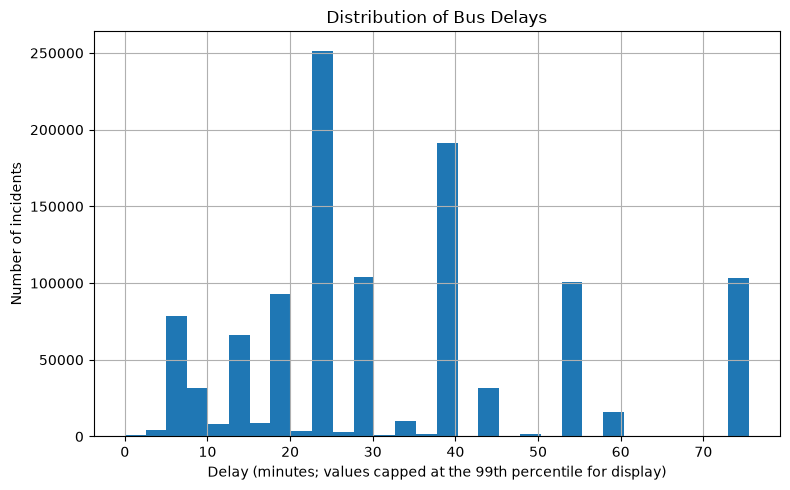

In [14]:
if "Delay_Minutes" in df.columns:
    plt.figure(figsize=(8, 5))
    df["Delay_Minutes"].dropna().clip(upper=df["Delay_Minutes"].quantile(0.99)).hist(bins=30)
    plt.xlabel("Delay (minutes; values capped at the 99th percentile for display)")
    plt.ylabel("Number of incidents")
    plt.title("Distribution of Bus Delays")
    plt.tight_layout()
    plt.show()

In [15]:
display(df["How_Long_Delayed"].value_counts(dropna=False).head(20))

How_Long_Delayed
16-30 Min    215213
NaN          179895
31-45 Min    179063
46-60 Min     99901
61-90 Min     96708
0-15 Min      75912
20 min        14747
30 min        13248
30MINS        12149
30 MINS       11515
15 min        10403
20 mins       10119
20 MINS       10018
20 MIN         9945
30 mins        9883
30 MIN         9847
15 mins        9654
20             8737
20mins         7036
30 MINS.       6867
Name: count, dtype: int64

In [16]:
display(df["Delay_Risk"].value_counts(dropna=False).rename(index={0.0: "Low risk (<30 min)", 1.0: "High risk (>=30 min)"}))

Delay_Risk
High risk (>=30 min)    562256
Low risk (<30 min)      549746
NaN                     182127
Name: count, dtype: int64

## 8. Prepare the model dataset

Rows without a readable delay are removed because their target class is unknown. The model uses only the five input columns below; it does **not** use `How_Long_Delayed`, `Delay_Minutes`, or `Delay_Risk` as predictors.

In [17]:
feature_names_raw = [
    "Run_Type",
    "Boro",
    "Breakdown_or_Running_Late",
    "School_Age_or_PreK",
    "Number_Of_Students_On_The_Bus"
]

missing_columns = [col for col in feature_names_raw + ["Delay_Risk"] if col not in df.columns]
if missing_columns:
    raise KeyError(f"Required columns missing from dataset: {missing_columns}")

model_df = df.loc[df["Delay_Risk"].notna(), feature_names_raw + ["Delay_Risk"]].copy()
model_df["Number_Of_Students_On_The_Bus"] = pd.to_numeric(
    model_df["Number_Of_Students_On_The_Bus"], errors="coerce"
)

# Fill predictor missing values only, after the target has been created.
for col in ["Run_Type", "Boro", "Breakdown_or_Running_Late", "School_Age_or_PreK"]:
    mode_values = model_df[col].mode(dropna=True)
    fill_value = mode_values.iloc[0] if not mode_values.empty else "Unknown"
    model_df[col] = model_df[col].fillna(fill_value).astype(str)

student_median = model_df["Number_Of_Students_On_The_Bus"].median()
if pd.isna(student_median):
    student_median = 0
model_df["Number_Of_Students_On_The_Bus"] = model_df[
    "Number_Of_Students_On_The_Bus"
].fillna(student_median)

model_df["Delay_Risk"] = model_df["Delay_Risk"].astype(int)
print("Rows used for training:", len(model_df))
print("\nTarget class counts:")
display(model_df["Delay_Risk"].value_counts().sort_index())

Rows used for training: 1112002

Target class counts:


Delay_Risk
0    549746
1    562256
Name: count, dtype: int64

## 9. Save the exact input choices for the Streamlit app

Use these category spellings in the app. This avoids options such as `AM Run` when the training data actually uses `Special Ed AM Run`.

In [18]:
input_options = {
    col: sorted(model_df[col].dropna().astype(str).unique().tolist())
    for col in ["Run_Type", "Boro", "Breakdown_or_Running_Late", "School_Age_or_PreK"]
}
for column, values in input_options.items():
    print(f"\n{column} ({len(values)} values):")
    print(values)

print("\nStudent count median used for missing values:", student_median)


Run_Type (10 values):
['General Ed AM Run', 'General Ed Field Trip', 'General Ed PM Run', 'Pre-K/EI', 'Project Read AM Run', 'Project Read Field Trip', 'Project Read PM Run', 'Special Ed AM Run', 'Special Ed Field Trip', 'Special Ed PM Run']

Boro (12 values):
['All Boroughs', 'Bronx', 'Brooklyn', 'Connecticut', 'Manhattan', 'Nassau County', 'New Jersey', 'Queens', 'Rockland County', 'Staten Island', 'Suffolk', 'Westchester']

Breakdown_or_Running_Late (2 values):
['Breakdown', 'Running Late']

School_Age_or_PreK (2 values):
['Pre-K', 'School-Age']

Student count median used for missing values: 0.0


## 10. Encode the categorical input columns

The model and `feature_columns.pkl` are built from the same encoded training data. In `app.py`, create dummies from the user's input and reindex to the saved feature list before predicting.

In [19]:
X_raw = model_df[feature_names_raw].copy()
y = model_df["Delay_Risk"].copy()

X = pd.get_dummies(X_raw, drop_first=True, dtype=int)
X = X.fillna(0)

feature_columns = X.columns.tolist()
print("Number of encoded features:", len(feature_columns))
display(pd.DataFrame({"Feature": feature_columns}))

Number of encoded features: 23


,Feature
0,Number_Of_Students_On_The_Bus
1,Run_Type_General Ed Field Trip
2,Run_Type_General Ed PM Run
3,Run_Type_Pre-K/EI
4,Run_Type_Project Read AM Run
5,Run_Type_Project Read Field Trip
6,Run_Type_Project Read PM Run
7,Run_Type_Special Ed AM Run
8,Run_Type_Special Ed Field Trip
9,Run_Type_Special Ed PM Run


## 11. Split data and train Logistic Regression

In [20]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

model = LogisticRegression(max_iter=1000)
model.fit(X_train, y_train)

y_pred = model.predict(X_test)
print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))

Training rows: 889601
Testing rows: 222401


In [27]:
df.to_csv("cleaned_bus_data.csv", index=False)

## 12. Evaluate the model

In [21]:
print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))
print("Precision:", round(precision_score(y_test, y_pred, zero_division=0), 4))
print("Recall:", round(recall_score(y_test, y_pred, zero_division=0), 4))
print("F1 Score:", round(f1_score(y_test, y_pred, zero_division=0), 4))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

print("\nActual test labels:")
print(y_test.value_counts().sort_index())

print("\nPredicted test labels:")
print(pd.Series(y_pred).value_counts().sort_index())

Accuracy: 0.6195
Precision: 0.6178
Recall: 0.6485
F1 Score: 0.6328

Confusion Matrix:


[[64843 45106]
 [39526 72926]]

Classification Report:
              precision    recall  f1-score   support

           0       0.62      0.59      0.61    109949
           1       0.62      0.65      0.63    112452

    accuracy                           0.62    222401
   macro avg       0.62      0.62      0.62    222401
weighted avg       0.62      0.62      0.62    222401


Actual test labels:
Delay_Risk
0    109949
1    112452
Name: count, dtype: int64

Predicted test labels:
0    104369
1    118032
Name: count, dtype: int64


## 13. Export model files for Streamlit

Run this cell after training. It saves:
- `delay_risk_model.pkl` — trained Logistic Regression model
- `feature_columns.pkl` — exact one-hot encoded columns expected by the model
- `input_options.pkl` — exact category options used by the model

In [22]:
joblib.dump(model, "delay_risk_model.pkl")
joblib.dump(feature_columns, "feature_columns.pkl")
joblib.dump(input_options, "input_options.pkl")

print("Saved files:")
print(" - delay_risk_model.pkl")
print(" - feature_columns.pkl")
print(" - input_options.pkl")

Saved files:
 - delay_risk_model.pkl
 - feature_columns.pkl
 - input_options.pkl


## 14. Check the saved files and expected features

In [23]:
print("Model file exists:", Path("delay_risk_model.pkl").exists())
print("Feature file exists:", Path("feature_columns.pkl").exists())
print("Input options file exists:", Path("input_options.pkl").exists())

loaded_model = joblib.load("delay_risk_model.pkl")
loaded_features = joblib.load("feature_columns.pkl")
loaded_options = joblib.load("input_options.pkl")

print("\nNumber of expected features:", len(loaded_features))
print("Input option counts:", {key: len(value) for key, value in loaded_options.items()})
print("\nFirst 20 expected features:")
print(loaded_features[:20])

Model file exists: True
Feature file exists: True
Input options file exists: True

Number of expected features: 23
Input option counts: {'Run_Type': 10, 'Boro': 12, 'Breakdown_or_Running_Late': 2, 'School_Age_or_PreK': 2}

First 20 expected features:
['Number_Of_Students_On_The_Bus', 'Run_Type_General Ed Field Trip', 'Run_Type_General Ed PM Run', 'Run_Type_Pre-K/EI', 'Run_Type_Project Read AM Run', 'Run_Type_Project Read Field Trip', 'Run_Type_Project Read PM Run', 'Run_Type_Special Ed AM Run', 'Run_Type_Special Ed Field Trip', 'Run_Type_Special Ed PM Run', 'Boro_Bronx', 'Boro_Brooklyn', 'Boro_Connecticut', 'Boro_Manhattan', 'Boro_Nassau County', 'Boro_New Jersey', 'Boro_Queens', 'Boro_Rockland County', 'Boro_Staten Island', 'Boro_Suffolk']


## Important note for `app.py`

The app must use category choices from `input_options.pkl` (or the exact values printed in Section 9). Its prediction input must use the same column names as `feature_names_raw`. Then apply `pd.get_dummies(input_data)` and `reindex(columns=features, fill_value=0)` before `model.predict(...)`.

A prediction is not guaranteed to be high risk: the output depends on the trained model and selected inputs. The metrics above show how well it performs on the held-out test data.